# Bab 11 — Neural Networks That Understand Language
**Acuan:** Andrew W. Trask, *Grokking Deep Learning*, Bab 11 (hlm. 187–208).

Tujuan: mengubah token menjadi indeks dan embedding, melatih klasifikasi sentimen, serta membaca kedekatan vektor. Buku memakai ulasan IMDB dan word analogy; di sini korpus kecil berbahasa Inggris ditulis sendiri untuk eksperimen offline. Hasil tidak mewakili akurasi IMDB.

## Representasi dan supervised NLP
Tokenizer menetapkan unit bahasa yang dilihat model. Vocabulary dipelajari hanya dari training; token baru masuk `<unk>`. Embedding adalah matriks E berukuran vocabulary × dimensi; mengambil baris E setara perkalian one-hot dengan E. Rata-rata embedding memberi representasi kalimat dengan panjang bervariasi, tetapi kehilangan urutan kata: “not good” dan “good not” memiliki rata-rata sama. Label sentimen menentukan arah representasi yang dipelajari, bukan makna universal kata.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(11)
texts = ['good enjoyable film', 'great enjoyable story', 'good great acting', 'wonderful good story',
         'bad boring film', 'terrible boring story', 'bad terrible acting', 'awful bad story']
y = np.array([1,1,1,1,0,0,0,0], dtype=float)
vocab = ['<unk>'] + sorted(set(' '.join(texts).split()))
index = {word:i for i,word in enumerate(vocab)}
encode = lambda text: np.array([index.get(w,0) for w in text.lower().split()])
sentences = [encode(t) for t in texts]
E = rng.normal(0,.15,(len(vocab),6)); w = rng.normal(0,.15,6); b = 0.
sigmoid = lambda z: 1/(1+np.exp(-np.clip(z,-30,30)))
print('Vocabulary:', vocab, 'embedding shape:', E.shape)

Vocabulary: ['<unk>', 'acting', 'awful', 'bad', 'boring', 'enjoyable', 'film', 'good', 'great', 'story', 'terrible', 'wonderful'] embedding shape: (12, 6)


## Embedding menerima gradien dari target
Untuk kalimat s, h adalah rata-rata embedding dan p=sigmoid(h·w+b). Binary cross-entropy memberi delta p−y. Gradien setiap kemunculan token adalah delta × w / panjang kalimat. Token berulang harus menjumlahkan gradien: `np.add.at` menangani indeks yang sama. Semua gradien dihitung sebelum bobot diubah.

Training accuracy: 1.0
good story 0.996
boring film 0.023
unknown film 0.524


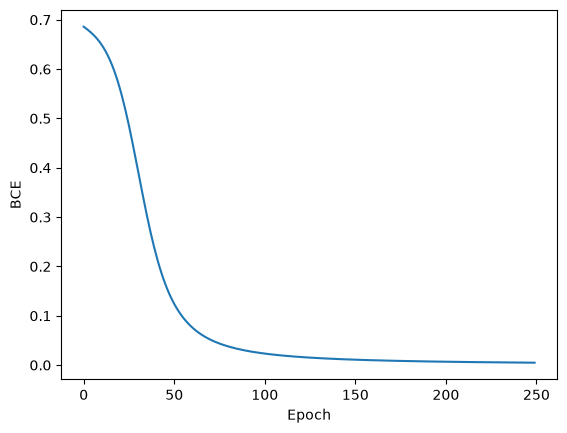

In [2]:
losses=[]
for epoch in range(250):
    gE=np.zeros_like(E); gw=np.zeros_like(w); gb=0.; loss=0.
    for ids,target in zip(sentences,y):
        h=E[ids].mean(axis=0); p=sigmoid(h@w+b); d=p-target
        loss -= target*np.log(p+1e-12)+(1-target)*np.log(1-p+1e-12)
        gw += d*h/len(y); gb += d/len(y)
        np.add.at(gE,ids,d*w/(len(ids)*len(y)))
    E-=.5*gE; w-=.5*gw; b-=.5*gb; losses.append(loss/len(y))
pred=np.array([sigmoid(E[ids].mean(axis=0)@w+b) for ids in sentences])
print('Training accuracy:', np.mean((pred>=.5)==y))
for text in ['good story', 'boring film', 'unknown film']:
    print(text, round(float(sigmoid(E[encode(text)].mean(axis=0)@w+b)),3))
plt.plot(losses); plt.xlabel('Epoch'); plt.ylabel('BCE'); plt.show()
assert losses[-1] < losses[0]

## Kedekatan dan analogi
Cosine similarity membandingkan arah vektor setelah normalisasi. Analogi seperti king−man+woman adalah hipotesis geometris tentang embedding yang dipelajari dari banyak konteks; delapan kalimat ini tidak cukup untuk mengharapkan analogi tersebut. Embedding sentimen bisa mendekatkan kata karena label serupa, bukan karena sinonim. `<unk>` tidak mendapat latihan di korpus ini, sehingga prediksi kalimat dengan token baru perlu ditafsirkan hati-hati.

In [3]:
norm=E/np.maximum(np.linalg.norm(E,axis=1,keepdims=True),1e-12)
query=index['good']; scores=norm@norm[query]
nearest=np.argsort(scores)[::-1][1:5]
print('Tetangga cosine good:', [(vocab[i],round(float(scores[i]),3)) for i in nearest])
assert np.allclose(E[encode('good bad')].mean(0), E[encode('bad good')].mean(0))

Tetangga cosine good: [('enjoyable', 0.976), ('great', 0.966), ('wonderful', 0.938), ('story', 0.431)]


## Ringkasan dan keterbatasan
Embedding dilatih bersama tujuan prediksi; bag-of-words menangani panjang bervariasi namun mengabaikan urutan. Eksperimen menunjukkan mekanisme pembelajaran, dengan akurasi training sebagai pemeriksaan kode. Evaluasi generalisasi memerlukan korpus lebih besar, split terpisah, penanganan negasi, dan pengujian token baru.